In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

file_name = "full-test.txt"
num_adaptive_iter = 0

Text(0.5, 0, 'N. of iterations')

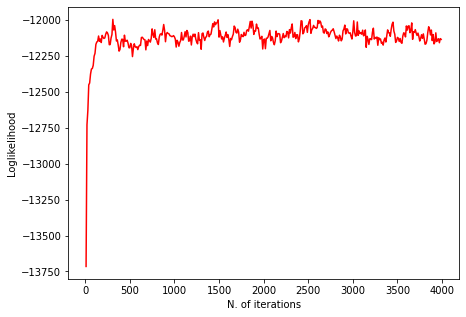

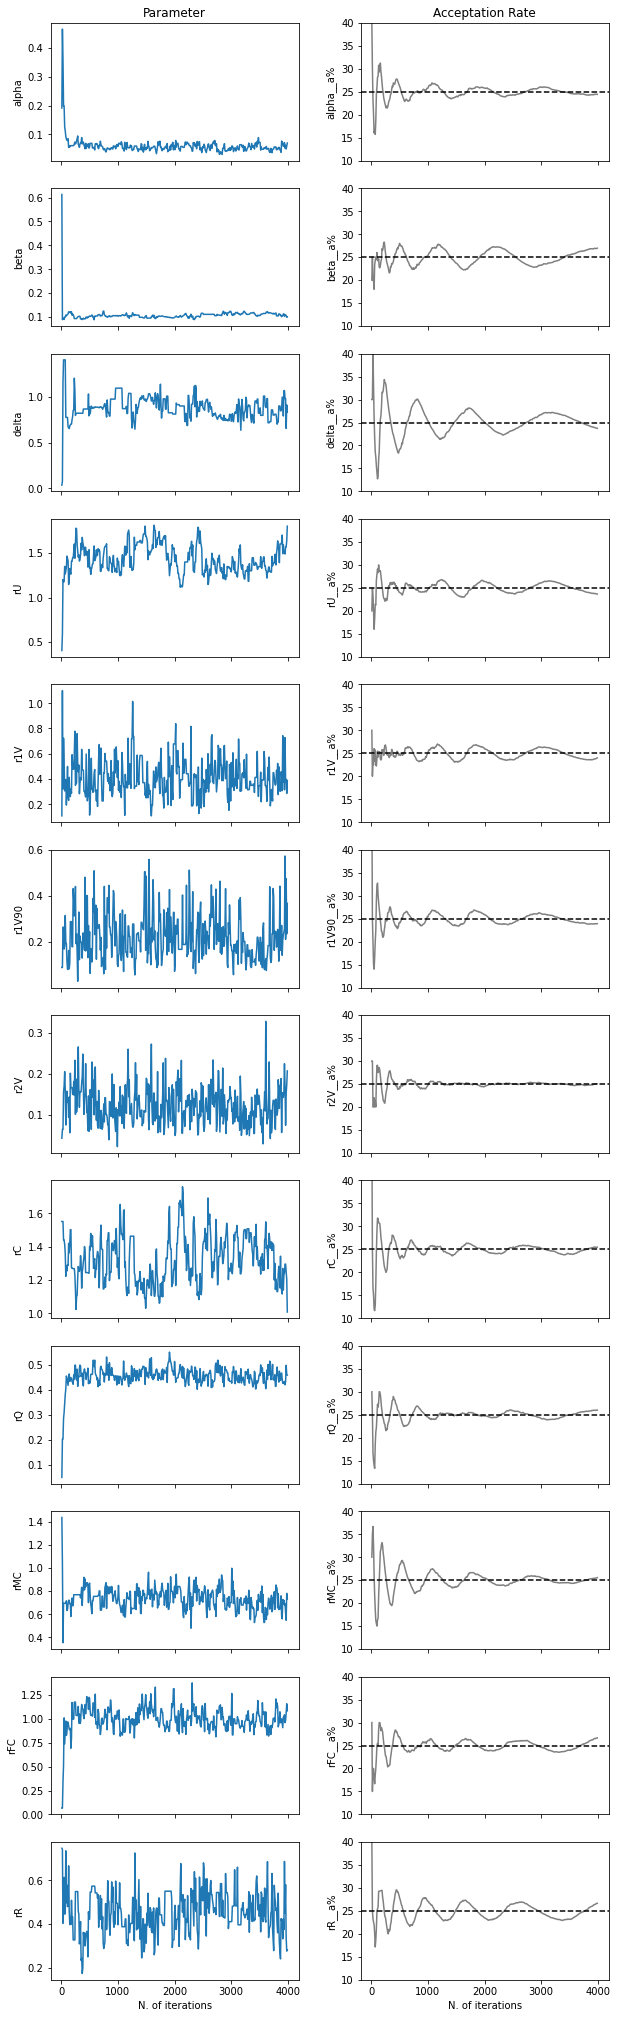

In [4]:
results = pd.read_csv(file_name, sep=" ", index_col="iter")
df = results[results.index > num_adaptive_iter]
cols = df.columns.to_list()
cols.remove('loglike')
param_names = [c for c in cols if "__a%" not in c]

plt.figure(figsize=(7,5))
plt.plot(df["loglike"], color = "red")
plt.xlabel("N. of iterations")
plt.ylabel("Loglikelihood")

fig, axes = plt.subplots(figsize=(10, 3 * len(param_names)),
                        nrows=len(param_names), ncols=2, sharex=True)
fig.subplots_adjust(wspace=0.25)

for i, p in enumerate(param_names) :
    axes[i, 0].plot(df.index, df[p], label=p)
    axes[i, 0].set_ylabel(p)
    axes[i, 1].plot(df.index, df[f"{p}__a%"], label=p, color="grey")
    axes[i, 1].set_ylabel(f"{p}__a%")
    axes[i, 1].set_ylim([10, 40])
    axes[i, 1].axhline(y=25, ls="--",color='black')


axes[0, 0].set_title("Parameter")
axes[0, 1].set_title("Acceptation Rate")
axes[-1, 0].set_xlabel("N. of iterations")
axes[-1, 1].set_xlabel("N. of iterations")